In [1]:
!pip install torch torchvision matplotlib scikit-learn


Device: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 479kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.54MB/s]


Epoch [1/5], Loss: 0.2843
Epoch [2/5], Loss: 0.1099
Epoch [3/5], Loss: 0.0724
Epoch [4/5], Loss: 0.0512
Epoch [5/5], Loss: 0.0394

Test Accuracy: 97.86%


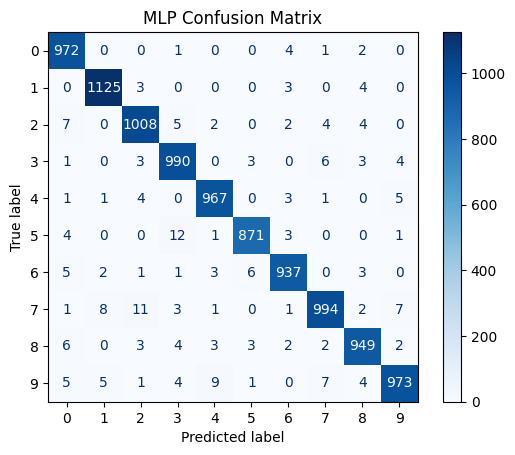

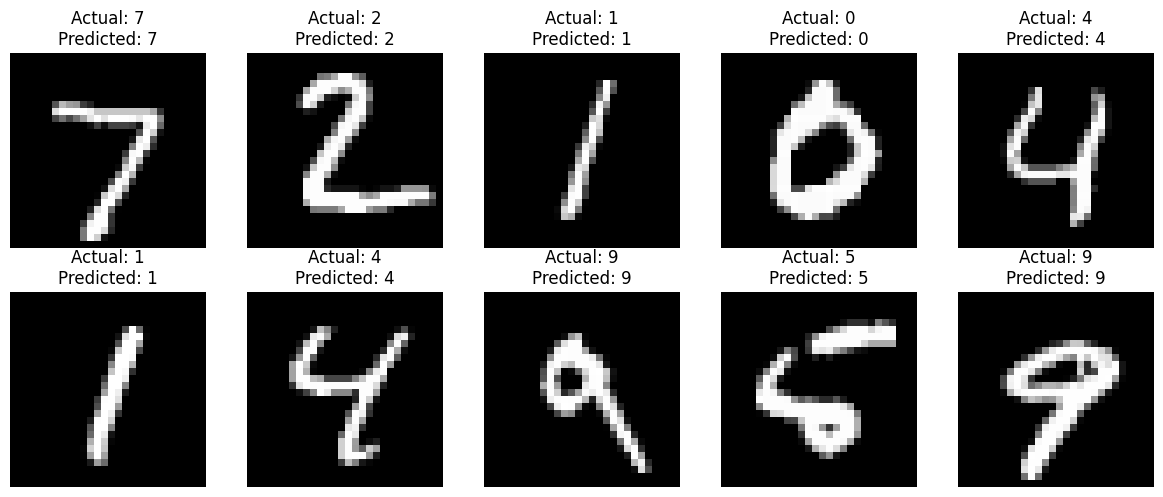

Model saved successfully!


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 2. Load and preprocess MNIST dataset
transform = transforms.ToTensor()

train_data = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_data, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_data, batch_size=1000, shuffle=False
)

# 3. Define the MLP model
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)

model = MLP().to(device)

# 4. Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 5. Train the model
epochs = 5

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch [{epoch + 1}/{epochs}], "
        f"Loss: {total_loss / len(train_loader):.4f}"
    )

# 6. Evaluate the model
model.eval()
correct = 0
total = 0
all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

accuracy = 100 * correct / total
print(f"\nTest Accuracy: {accuracy:.2f}%")

# 7. Display confusion matrix
cm = confusion_matrix(all_labels, all_predictions)

ConfusionMatrixDisplay(
    confusion_matrix=cm
).plot(cmap="Blues")

plt.title("MLP Confusion Matrix")
plt.show()

# 8. Display sample predictions
images, labels = next(iter(test_loader))

model.eval()

with torch.no_grad():
    outputs = model(images.to(device))
    predictions = outputs.argmax(dim=1).cpu()

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(images[i].squeeze(), cmap="gray")

    plt.title(
        f"Actual: {labels[i]}\nPredicted: {predictions[i]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

# 9. Save the trained model
torch.save(model.state_dict(), "mlp_digit_model.pth")

print("Model saved successfully!")